# Calibrating Fisher forecasts of the core size against inference

How well does a Fisher forecast predict the uncertainty on the CIS core size $x_c$ that full Bayesian inference finds? This notebook compares the two for the LIGO mass scan of the paper: a lens with $x_c = 0.02$ at $y = 0.3$, for $M_{Lz} = 3$ to $1000\,M_\odot$, with the 30+30 $M_\odot$ benchmark source at 500 Mpc.

1. Read the width of the $x_c$ posterior from the shipped mass-scan samples.
2. Read the Fisher covariance of $(\ln M_{Lz}, y, x_c)$ at the same points, and restrict the Fisher Gaussian to the prior used in inference.
3. Compare the two (the paper's calibration figure).
4. Translate the same posteriors into the SIDM cross section and show how the bound tightens with lens mass (the paper's SIDM figure).

The Fisher grid ships in `data/core_fisher_LIGO_CIS.npz`. To recompute it, run `python scripts/1_fisher/core_size_fisher.py LIGO` (about 15 minutes on 112 cores, `slurm/core_size_fisher.sh`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from infer_with_fiona import paths, posteriors

## 1. Posterior width of $x_c$

The mass-scan runs sample $x_c$ (stored as `lp`) with a flat prior on $[0, 1]$. Where the data carry no information on the core, the posterior width approaches the width of that prior, $1/\sqrt{12} \approx 0.29$.

In [2]:
MASSES = [3, 10, 30, 100, 300, 1000]
XC_TRUE, Y_TRUE = 0.02, 0.3
pe_std = {m: posteriors.load_fiona(posteriors.fiona_label('CIS', Y_TRUE, XC_TRUE, mlz=m))[0]['lp'].std() for m in MASSES}
pd.Series(pe_std, name='posterior std of x_c').rename_axis('M_Lz').to_frame().T

M_Lz,3,10,30,100,300,1000
posterior std of x_c,0.287802,0.277873,0.200071,0.125345,0.031577,0.011368


## 2. The Fisher forecast, restricted to the prior

The Fisher grid holds, at each $(x_c, M_{Lz}, y)$, the covariance of $(\ln M_{Lz}, y, x_c)$ after marginalizing over the distance, the phase and the arrival time, as in inference. Where the data are weak this Gaussian is much wider than the prior, and part of it lies at unphysical values such as $x_c < 0$. Comparing its raw $\sigma(x_c)$ with the posterior would count that region.

The inference prior is flat in $(\ln M_{Lz}, y, x_c)$: log-uniform $M_{Lz} \in [0.1, 2000]\,M_\odot$, $y \in [0.1, 5]$, $x_c \in [0, 1]$. So the Fisher approximation of the posterior is the Fisher Gaussian truncated to that box. We draw from the Gaussian, keep the draws inside the box, and take the standard deviation of $x_c$. (The prior also excludes a narrow band around the caustic, which we do not remove here.)

In [3]:
grid = np.load(paths.CORE_FISHER_GRID)
LNM_BOX, Y_BOX, XC_BOX = (np.log(0.1), np.log(2000.0)), (0.1, 5.0), (0.0, 1.0)
Z = np.random.default_rng(1).standard_normal((400000, 3))      # the same normal draws for every point


def truncated_std(cov, truth):
    # std of x_c for the Gaussian N(truth, cov) in (ln M_Lz, y, x_c), restricted to the prior box
    w, V = np.linalg.eigh(cov)
    s = np.asarray(truth) + Z @ (V * np.sqrt(np.clip(w, 0, None))).T
    inside = ((s[:, 0] >= LNM_BOX[0]) & (s[:, 0] <= LNM_BOX[1]) & (s[:, 1] >= Y_BOX[0]) & (s[:, 1] <= Y_BOX[1])
              & (s[:, 2] >= XC_BOX[0]) & (s[:, 2] <= XC_BOX[1]))
    return s[inside, 2].std()


i, k = list(grid['x_c']).index(XC_TRUE), list(grid['y']).index(Y_TRUE)
M_grid = grid['M_Lz']
raw = grid['sigma_xc_t'][i, :, k]                                        # with t_c, as in inference
trunc = np.array([truncated_std(grid['cov_t'][i, j, k], (np.log(M), Y_TRUE, XC_TRUE)) for j, M in enumerate(M_grid)])

# the PE masses fall between grid masses: interpolate in log M_Lz
interp = lambda v, m: 10 ** np.interp(np.log10(m), np.log10(M_grid), np.log10(v))
CAL = pd.DataFrame({'M_Lz': MASSES, 'posterior std': [pe_std[m] for m in MASSES],
                    'Fisher sigma (no prior)': [interp(raw, m) for m in MASSES],
                    'Fisher std (truncated to prior)': [interp(trunc, m) for m in MASSES]})
CAL['posterior / Fisher (truncated)'] = CAL['posterior std'] / CAL['Fisher std (truncated to prior)']
CAL.round(3)

,M_Lz,posterior std,Fisher sigma (no prior),Fisher std (truncated to prior),posterior / Fisher (truncated)
0,3,0.288,24.091,0.296,0.972
1,10,0.278,5.842,0.287,0.967
2,30,0.200,1.566,0.269,0.745
3,100,0.125,0.473,0.159,0.788
4,300,0.032,0.131,0.072,0.441
5,1000,0.011,0.014,0.012,0.934


Without the prior, the Fisher $\sigma(x_c)$ exceeds the width of the prior by up to two orders of magnitude at low lens mass, where it only says that the data carry no information. Truncated to the prior, it reproduces the posterior there. At $M_{Lz} = 1000\,M_\odot$, where the data dominate, the two methods agree to 10%. In between ($M_{Lz} = 30$ to $300\,M_\odot$) the Fisher forecast is conservative by a factor of up to about two, because the likelihood there is far from Gaussian.

## 3. The calibration figure

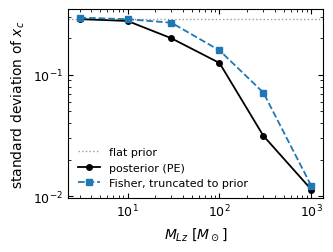

In [4]:
paths.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'legend.fontsize': 8, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    ax.axhline(1 / np.sqrt(12), color='0.6', ls=':', lw=1, label='flat prior')
    ax.loglog(CAL['M_Lz'], CAL['posterior std'], 'o-', color='k', ms=4, lw=1.3, label='posterior (PE)')
    ax.loglog(CAL['M_Lz'], CAL['Fisher std (truncated to prior)'], 's--', color='tab:blue', ms=4, lw=1.3,
              label='Fisher, truncated to prior')
    ax.set(xlabel=r'$M_{Lz}\ [M_\odot]$', ylabel=r'standard deviation of $x_c$')
    ax.legend(frameon=False, loc='lower left')
    fig.tight_layout()
    for ext in ('pdf', 'png'):
        fig.savefig(paths.FIGURES_DIR / f'calibration_width.{ext}', dpi=300, bbox_inches='tight')
    plt.show()

## 4. SIDM cross section along the mass scan

Reading the CIS core as an SIDM core, the core-formation condition $\langle\sigma v\rangle\,\rho(r_c)\,t_{\rm age}/m \simeq 1$ on the CIS profile gives the cross section per unit mass,
$$\frac{\sigma}{m} = \frac{4\pi G\,(x_c\,\xi_0)^2}{\sigma_v^2\,\langle v\rangle\,t_{\rm age}},\qquad \sigma_v^2 = \frac{\xi_0\,c^2}{4\pi D},\qquad \langle v\rangle = \frac{4\sigma_v}{\sqrt{\pi}},$$
where $\xi_0$ is the Einstein radius, $D = D_L D_{LS}/D_S$, and $t_{\rm age} = 5$ Gyr. The lens redshift is T23's pessimistic choice, the one that maximizes $(1+z_L)\,d_{\rm eff}$. Each posterior sample is converted with its own $M_{Lz}$ and $x_c$. At $M_{Lz} = 3$ and $10\,M_\odot$ the $x_c$ posterior fills its prior, so only $M_{Lz} \ge 30\,M_\odot$ are shown.

In [5]:
from scipy.constants import G as G_SI, c as C_SI
from infer_with_fiona import dm_conversions as D

z_S = D.z_source(500.0)                                   # the injected source, d_L = 500 Mpc
z_L = D.zL_pessimistic(z_S)
KPC_M, GPC_M, GYR_S = 3.0856775814913673e19, 3.0856775814913673e25, 3.15576e16
D_M = (1 + z_L) * D.d_eff_Gpc(z_L, z_S) * GPC_M           # D_L D_LS / D_S [m]


def sigma_v_kms(mlz):
    # CIS velocity dispersion from the Einstein radius
    return np.sqrt(D.xi0_kpc(mlz, z_L, z_S) * KPC_M * C_SI ** 2 / (4 * np.pi * D_M)) / 1e3


def sigma_over_m(xc, mlz, t_age_gyr=5.0):
    # physical sigma/m [cm^2/g] from the core-formation condition on the CIS profile
    xi0 = D.xi0_kpc(mlz, z_L, z_S) * KPC_M
    sv = sigma_v_kms(mlz) * 1e3
    v = 4 / np.sqrt(np.pi) * sv
    return 4 * np.pi * G_SI * (np.asarray(xc) * xi0) ** 2 / (sv ** 2 * v * t_age_gyr * GYR_S) * 10.0


SCAN = [30, 100, 300, 1000]
SIG = {}
rows = []
for m in SCAN:
    s, _ = posteriors.load_fiona(posteriors.fiona_label('CIS', Y_TRUE, XC_TRUE, mlz=m))
    SIG[m] = sigma_over_m(np.maximum(s['lp'], 1e-6), s['MLz'])
    rows.append({'M_Lz': m, '<v> [km/s]': 4 / np.sqrt(np.pi) * float(sigma_v_kms(m)),
                 'x_c 95% UL': np.percentile(s['lp'], 95), 'sigma/m 95% UL [cm2/g]': np.percentile(SIG[m], 95),
                 'sigma/m injected [cm2/g]': float(sigma_over_m(XC_TRUE, m))})
pd.DataFrame(rows).set_index('M_Lz').style.format('{:.3g}')

,[km/s],x_c 95% UL,sigma/m 95% UL [cm2/g],sigma/m injected [cm2/g]
M_Lz,,,,
30,2.87,0.58,3.12e-06,2.56e-09
100,3.87,0.428,1.83e-06,3.46e-09
300,5.1,0.114,1.62e-07,4.55e-09
1000,6.89,0.0393,2.39e-08,6.15e-09


The $x_c$ upper limit falls from 0.58 at $M_{Lz} = 30\,M_\odot$ to 0.04 at $1000\,M_\odot$, so the bound on $\sigma/m$ tightens by about two orders of magnitude, although heavier lenses have larger physical cores ($\xi_0 \propto M_{Lz}^{1/2}$) and faster halos ($\langle v\rangle \propto M_{Lz}^{1/4}$). At $1000\,M_\odot$ the bound approaches the injected value.

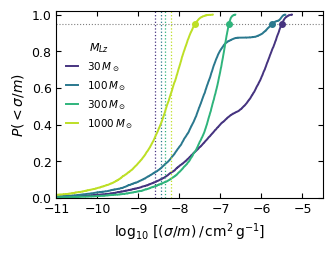

In [6]:
COLS = dict(zip(SCAN, plt.cm.viridis(np.linspace(0.15, 0.9, len(SCAN)))))
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'legend.fontsize': 7.5, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    for m in SCAN:
        x = np.sort(np.log10(SIG[m]))
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', color=COLS[m], lw=1.4,
                label=rf'${m:g}\,M_\odot$')
        ax.plot([np.log10(np.percentile(SIG[m], 95))], [0.95], 'o', color=COLS[m], ms=4, zorder=5)
        ax.axvline(np.log10(float(sigma_over_m(XC_TRUE, m))), color=COLS[m], lw=0.9, ls=':')
    ax.axhline(0.95, color='0.5', ls=':', lw=0.8)
    ax.set(xlabel=r'$\log_{10}\,[(\sigma/m)\,/\,{\rm cm^2\,g^{-1}}]$', ylabel=r'$P(<\sigma/m)$',
           xlim=(-11, -4.5), ylim=(0, 1.02))
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(0.0, 0.6), title=r'$M_{Lz}$', title_fontsize=8,
              handlelength=1.2)
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'sidm_mass_scan.png', dpi=300, bbox_inches='tight')
    plt.show()

Cumulative posterior of $\sigma/m$ for each lens mass. Dots mark the 95% upper limits, and dotted vertical lines the injected values ($x_c = 0.02$).